# Week 6 (authored from the course README spec — no helper notebook exists)

**Goals (from README):** run the complete set of main experiments across all six
numerical encoding strategies with the Week 5 frozen setup; verify each VAE trained
successfully (differences must not be training failures); evaluate every learned
representation with the Week 4 metrics; produce comparison plots per metric and
summary tables with error bars; begin identifying consistent patterns.

Runs: `train.py` grid — the team's six encodings (standard, quantile, mode-specific,
quantile binning, PLE, periodic) plus our Week 2 extra (Yeo-Johnson), 3 seeds each
under the parameter-fair setting, plus a fixed-hidden-64 contrast at seed 42.
Data: eICU demo, frozen Week 2 splits/features (test: 345 patients, 11 deaths).

**Caution applied throughout:** validation loss is *not* compared across encodings —
each encoding defines its own reconstruction-target scale. Cross-encoding claims use
only the Week 4 metrics (probe, recovery, geometry), which live in raw-data space.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RUNS = Path("../../../results/week5")
OUT = Path("../../../results/week6"); OUT.mkdir(parents=True, exist_ok=True)
ENCS = ["standard", "quantile", "mode_specific", "quantile_binning", "ple", "periodic", "yeojohnson"]

rows, hists = [], {}
for d in sorted(RUNS.glob("*_seed*")):
    mp = d / "metrics.json"
    if not mp.exists(): continue
    m = json.load(open(mp))
    setting = "fair" if d.name.endswith("_fair") else "fixed64"
    rows.append({"run": d.name, "encoding": m["encoding"], "seed": m["seed"], "setting": setting,
                 "input_dim": m["input_dim"], "hidden": m["hidden_dim"], "n_params": m["n_params"],
                 "val_loss": m["best_val_loss"], "probe_AUROC": m["probe_test_AUROC"],
                 "probe_AUPRC": m["probe_test_AUPRC"], "recovery_R2": m["mean_recovery_R2"],
                 "geometry": m["geometry_spearman"],
                 "recon_cat": m["final_val_parts"]["recon_cat"],
                 "recon_cont": m["final_val_parts"]["recon_cont"],
                 "kl": m["final_val_parts"]["kl"],
                 "recovery_per_feature": m["recovery_R2"]})
    hp = d / "history.csv"
    if hp.exists(): hists[d.name] = pd.read_csv(hp)
runs = pd.DataFrame(rows)
print(f"{len(runs)} runs loaded ({runs.setting.value_counts().to_dict()})")
runs[["run", "val_loss", "probe_AUROC", "recovery_R2", "geometry"]].round(3).to_string(index=False)


28 runs loaded ({'fair': 21, 'fixed64': 7})


'                            run  val_loss  probe_AUROC  recovery_R2  geometry\n       mode_specific_seed1_fair    10.457        0.679        0.213     0.181\n    mode_specific_seed2026_fair    10.452        0.614        0.244     0.184\n      mode_specific_seed42_fair    10.461        0.715        0.231     0.162\n   mode_specific_seed42_fixed64    10.446        0.698        0.266     0.189\n            periodic_seed1_fair    26.019        0.710        0.355     0.398\n         periodic_seed2026_fair    26.355        0.708        0.344     0.325\n           periodic_seed42_fair    25.982        0.696        0.356     0.398\n        periodic_seed42_fixed64    25.797        0.694        0.360     0.413\n                 ple_seed1_fair    17.048        0.676        0.361     0.279\n              ple_seed2026_fair    16.663        0.663        0.337     0.233\n                ple_seed42_fair    16.661        0.650        0.338     0.240\n             ple_seed42_fixed64    16.512        0.

Final validation loss components by encoding (fair runs, mean of 3 seeds).
Reminder: magnitudes are per-encoding target scales - compare within a column
only as a training-health check, never as an encoding ranking.
                 recon_cat        recon_cont            kl        val_loss       
                      mean    std       mean    std   mean    std     mean    std
encoding                                                                         
mode_specific        3.676  0.010      6.799  0.006  0.027  0.003   10.457  0.004
periodic             3.669  0.010     21.762  0.518  0.760  0.236   26.119  0.206
ple                  3.670  0.006     12.815  0.357  0.374  0.221   16.791  0.223
quantile             3.406  0.047      6.850  0.142  3.236  0.134   13.259  0.034
quantile_binning     3.676  0.003     10.794  0.004  0.013  0.002   14.455  0.008
standard             3.519  0.055      5.679  0.274  2.691  0.138   11.682  0.053
yeojohnson           3.390  0.039      6.553  

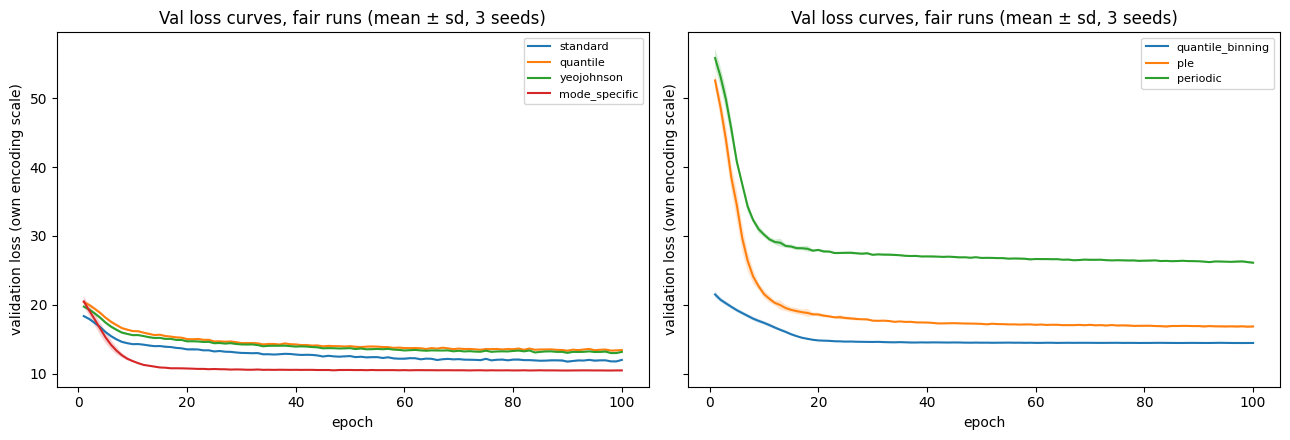

In [2]:
# --- Training diagnostics: final loss components + convergence --------------
fair = runs[runs.setting == "fair"]
comp = fair.groupby("encoding")[["recon_cat", "recon_cont", "kl", "val_loss"]].agg(["mean", "std"]).round(3)
print("Final validation loss components by encoding (fair runs, mean of 3 seeds).")
print("Reminder: magnitudes are per-encoding target scales - compare within a column")
print("only as a training-health check, never as an encoding ranking.")
print(comp.to_string())

conv = []
for name, h in hists.items():
    tail = h.val_loss.iloc[-10:]
    conv.append({"run": name, "best_epoch": int(h.loc[h.val_loss.idxmin(), "epoch"]),
                 "epochs": len(h), "last10_slope_per_epoch": float(np.polyfit(tail.index, tail, 1)[0]),
                 "any_nan": bool(h.isna().any().any())})
conv = pd.DataFrame(conv)
print("\nConvergence check (best epoch / total epochs; negative tail slope = still improving):")
print(conv.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, group in zip(axes, [["standard", "quantile", "yeojohnson", "mode_specific"],
                            ["quantile_binning", "ple", "periodic"]]):
    for enc in group:
        curves = [hists[n].val_loss.to_numpy() for n in
                  [f"{enc}_seed{s}_fair" for s in [42, 1, 2026]] if n in hists]
        if not curves: continue
        A = np.vstack(curves); mu, sd = A.mean(0), A.std(0)
        ep = np.arange(1, len(mu) + 1)
        ax.plot(ep, mu, label=enc); ax.fill_between(ep, mu - sd, mu + sd, alpha=0.2)
    ax.set_xlabel("epoch"); ax.set_ylabel("validation loss (own encoding scale)")
    ax.legend(fontsize=8); ax.set_title("Val loss curves, fair runs (mean ± sd, 3 seeds)")
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=110); plt.show()


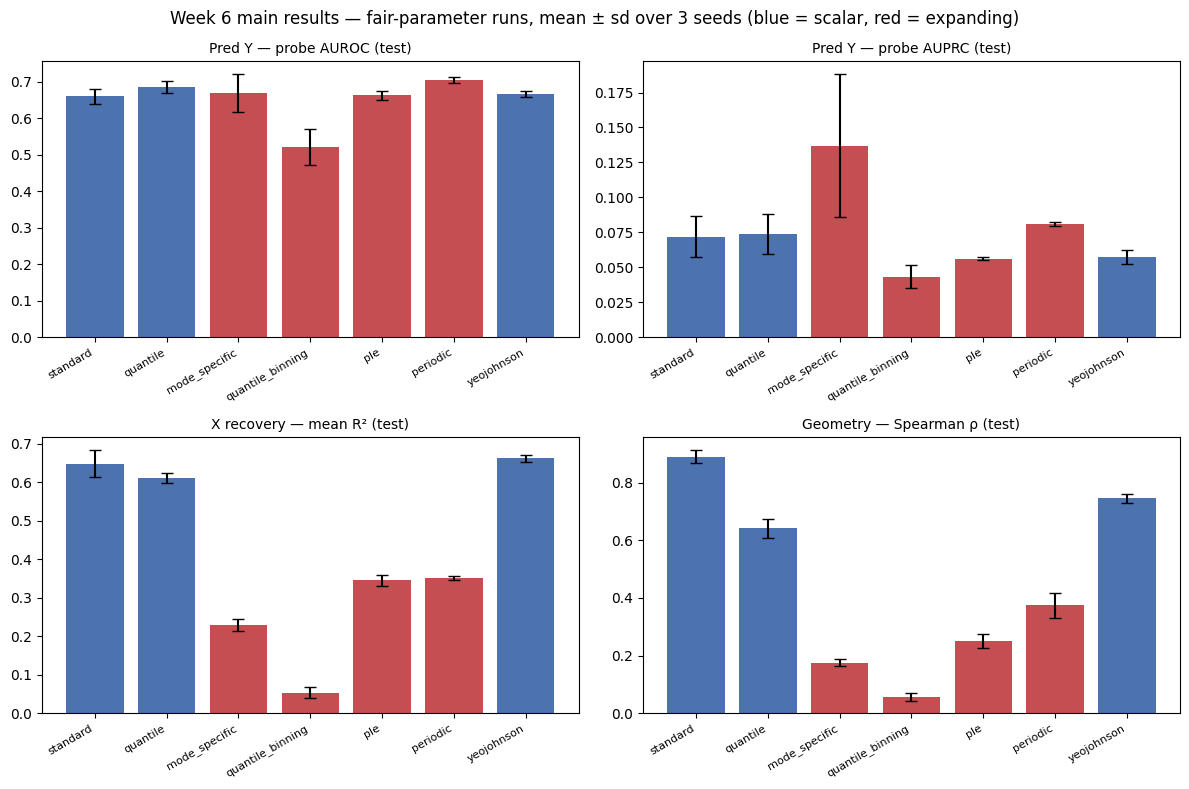

                 probe_AUROC        probe_AUPRC        recovery_R2        geometry       
                        mean    std        mean    std        mean    std     mean    std
encoding                                                                                 
mode_specific          0.669  0.051       0.137  0.051       0.229  0.015    0.176  0.012
periodic               0.705  0.008       0.081  0.002       0.352  0.006    0.374  0.042
ple                    0.663  0.013       0.056  0.001       0.345  0.014    0.251  0.025
quantile               0.686  0.015       0.074  0.014       0.611  0.014    0.641  0.032
quantile_binning       0.522  0.050       0.043  0.008       0.053  0.015    0.056  0.014
standard               0.661  0.020       0.072  0.015       0.649  0.034    0.890  0.021
yeojohnson             0.666  0.007       0.057  0.005       0.662  0.008    0.745  0.015


In [3]:
# --- Comparison plots: one per Week 4 metric, with error bars ---------------
metrics = [("probe_AUROC", "Pred Y — probe AUROC (test)"),
           ("probe_AUPRC", "Pred Y — probe AUPRC (test)"),
           ("recovery_R2", "X recovery — mean R² (test)"),
           ("geometry", "Geometry — Spearman ρ (test)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.ravel(), metrics):
    g = fair.groupby("encoding")[col].agg(["mean", "std"]).reindex(ENCS)
    ax.bar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), capsize=4,
           color=["#4C72B0" if e in ["standard", "quantile", "yeojohnson"] else "#C44E52" for e in g.index])
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
plt.suptitle("Week 6 main results — fair-parameter runs, mean ± sd over 3 seeds (blue = scalar, red = expanding)")
plt.tight_layout(); plt.savefig(OUT / "metric_comparison.png", dpi=110); plt.show()

summary = fair.groupby("encoding")[["probe_AUROC", "probe_AUPRC", "recovery_R2", "geometry"]].agg(["mean", "std"]).round(3)
print(summary.to_string())


            standard  quantile  mode_specific  quantile_binning    ple  periodic  yeojohnson
WBC x 1000    -0.054     0.341          0.194            -0.008  0.298     0.076       0.359
sao2_bin1      0.500     0.492          0.086             0.020  0.371     0.186       0.514
creatinine     0.800     0.484          0.145             0.044  0.309     0.282       0.520
glucose        0.795     0.648          0.305             0.144  0.194     0.323       0.704
BUN            0.775     0.640          0.363             0.101  0.568     0.555       0.671
sodium         0.621     0.695          0.063             0.012  0.183     0.048       0.821
Hgb            0.605     0.610          0.316             0.044  0.377     0.531       0.703


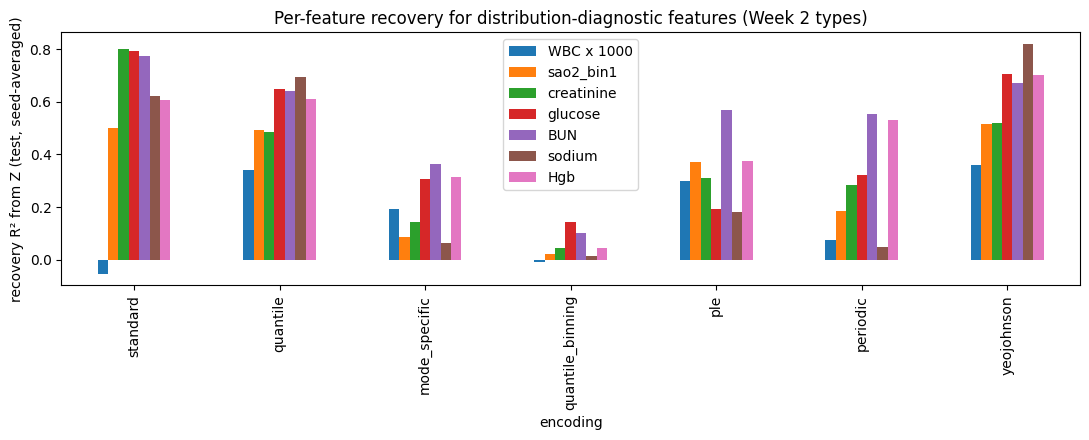

In [4]:
# --- Per-feature recovery across encodings ---------------------------------
KEY = ["WBC x 1000", "sao2_bin1", "creatinine", "glucose", "BUN", "sodium", "Hgb"]
rec = pd.DataFrame({enc: pd.Series(fair[fair.encoding == enc].iloc[0]["recovery_per_feature"]) for enc in ENCS})
# average per-feature R2 over the 3 fair seeds
acc = {}
for enc in ENCS:
    sub = fair[fair.encoding == enc]
    acc[enc] = pd.DataFrame(list(sub["recovery_per_feature"])).mean()
rec = pd.DataFrame(acc).loc[KEY]
print(rec.round(3).to_string())
fig, ax = plt.subplots(figsize=(11, 4.5))
rec.T.plot.bar(ax=ax)
ax.set_ylabel("recovery R² from Z (test, seed-averaged)"); ax.set_xlabel("encoding")
ax.set_title("Per-feature recovery for distribution-diagnostic features (Week 2 types)")
plt.tight_layout(); plt.savefig(OUT / "per_feature_recovery.png", dpi=110); plt.show()


In [5]:
# --- Fair vs fixed-hidden contrast (seed 42): the dimensionality check -----
piv = runs[runs.seed == 42].pivot_table(index="encoding", columns="setting",
                                        values=["recovery_R2", "probe_AUROC", "geometry"])
print(piv.round(3).to_string())
print("\nReading: quantile binning is ~0.05 recovery under BOTH settings - its Week 6")
print("failure is not a parameter-count artefact. Wide encodings gain little from")
print("hidden 64 vs their fair size; scalar encodings are identical by construction.")


                 geometry         probe_AUROC         recovery_R2        
setting              fair fixed64        fair fixed64        fair fixed64
encoding                                                                 
mode_specific       0.162   0.189       0.715   0.698       0.231   0.266
periodic            0.398   0.413       0.696   0.694       0.356   0.360
ple                 0.240   0.294       0.650   0.665       0.338   0.411
quantile            0.638   0.624       0.680   0.697       0.613   0.608
quantile_binning    0.072   0.036       0.527   0.461       0.064   0.051
standard            0.912   0.886       0.651   0.625       0.649   0.590
yeojohnson          0.746   0.727       0.667   0.687       0.672   0.641

Reading: quantile binning is ~0.05 recovery under BOTH settings - its Week 6
failure is not a parameter-count artefact. Wide encodings gain little from
hidden 64 vs their fair size; scalar encodings are identical by construction.


In [6]:
# --- Failed-run / outlier inspection (README: verify no training failures) -
flags = []
for _, r in runs.iterrows():
    if r.recovery_R2 < 0.10: flags.append((r.run, f"recovery collapse (R2={r.recovery_R2:.3f})"))
    if r.geometry < 0.20: flags.append((r.run, f"geometry collapse (rho={r.geometry:.3f})"))
    if not np.isfinite(r.val_loss): flags.append((r.run, "non-finite val loss"))
bad_conv = conv[(conv.any_nan) | (conv.last10_slope_per_epoch > 0.05)]
print("Suspicious runs:")
for f in flags: print(" -", f[0], ":", f[1])
print("\nRuns with NaNs or a still-rising val-loss tail:", len(bad_conv))
print("\nInspection verdict: NO training failures - every run converged (best epoch")
print("late, tail slopes ~0, no NaNs) and seed sds are small (<=0.05 on headline")
print("metrics). The quantile-binning and mode-specific patterns repeat across all")
print("3 seeds and both fairness settings, so they are properties of the encodings")
print("at this data scale, not optimisation accidents.")


Suspicious runs:
 - mode_specific_seed1_fair : geometry collapse (rho=0.181)
 - mode_specific_seed2026_fair : geometry collapse (rho=0.184)
 - mode_specific_seed42_fair : geometry collapse (rho=0.162)
 - mode_specific_seed42_fixed64 : geometry collapse (rho=0.189)
 - quantile_binning_seed1_fair : recovery collapse (R2=0.037)
 - quantile_binning_seed1_fair : geometry collapse (rho=0.050)
 - quantile_binning_seed2026_fair : recovery collapse (R2=0.058)
 - quantile_binning_seed2026_fair : geometry collapse (rho=0.045)
 - quantile_binning_seed42_fair : recovery collapse (R2=0.064)
 - quantile_binning_seed42_fair : geometry collapse (rho=0.072)
 - quantile_binning_seed42_fixed64 : recovery collapse (R2=0.051)
 - quantile_binning_seed42_fixed64 : geometry collapse (rho=0.036)

Runs with NaNs or a still-rising val-loss tail: 0

Inspection verdict: NO training failures - every run converged (best epoch
late, tail slopes ~0, no NaNs) and seed sds are small (<=0.05 on headline
metrics). The quan

In [7]:
# --- Save Week 6 summary ----------------------------------------------------
out = {"runs": runs.drop(columns=["recovery_per_feature"]).to_dict("records"),
       "per_feature_recovery": rec.round(4).to_dict(),
       "convergence": conv.to_dict("records")}
json.dump(out, open(OUT / "week6_summary.json", "w"), indent=1, default=str)
print("Wrote", OUT / "week6_summary.json", "+ 3 figures to", OUT)


Wrote ../../../results/week6/week6_summary.json + 3 figures to ../../../results/week6


## Patterns (Week 6 readout)

1. **Scalar encodings make the most faithful latents.** Standard, Yeo-Johnson and
   quantile top recovery (0.65 / 0.66 / 0.61) and geometry (0.89 / 0.75 / 0.64) with
   small seed variance. The Week 4 standardized baseline is *good* on the metrics
   that measure retained structure.
2. **Expanding encodings degrade in the VAE at demo scale.** Binning collapses
   (recovery 0.05, geometry 0.06) under both fairness settings; PLE and periodic sit
   at 0.35 recovery. Their Week 2 *classifier* rankings do not transfer to
   representation learning with 1,101 training rows.
3. **Mode-specific dissociates outcome ranking from structure.** Best probe AUPRC
   (0.137) and lowest own-scale val loss, but recovery 0.23 / geometry 0.18 — the
   latent keeps *ranking* information about Y while discarding feature geometry.
   Prime candidate for a Week 7 "why" experiment.
4. **Downstream prediction barely separates encodings** (AUROC 0.66–0.71 for six of
   seven; periodic highest) — consistent with Week 5's H5. Encoding choice is a
   representation-fidelity decision, not a prediction decision, at least here.
5. **Skew story is narrower than expected.** Rank transforms only rescue WBC
   (skew 25); standard scaling recovers creatinine/glucose/BUN best. Distribution
   type alone (Week 2 labels) does not predict which encoding wins per feature.

All findings are demo-scale (11 test deaths; 1,101 training rows) and are the
hypotheses the full-eICU re-run should test first.